
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Ótimo trabalho nesta reenvio! Você corrigiu os problemas que estavam bloqueando seu projeto: o terceiro teste z agora usa uma definição única e consistente, e sua conclusão relata corretamente o tamanho da amostra e os valores-p, mantendo a meta de 10% separada da significância estatística. Em projetos futuros, concentre-se em alinhar suas interpretações escritas dos gráficos de eventos diários com os números exatos das suas tabelas e gráficos, e em apresentar as diferenças entre grupos como hipóteses a serem verificadas. Continue com essa análise cuidadosa e honesta!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>


Este teste A/B busca verificar se as mudanças relacionadas à introdução de um sistema de recomendação melhora a conversão dos usuários no funil product_page - product_cart - purchase, de modo que seja esperado pelo menos 10% de aumento em cada etapa, dentro de uma janela de 14 dias após o cadastro, com 6000 participantes esperados.

<div class="alert alert-block alert-success">

Começar com uma declaração clara do objetivo do estudo é um ótimo ponto de partida. Você apresenta a hipótese (um recomendador melhor deve aumentar a conversão), as etapas do funil, o ganho esperado de pelo menos 10% por etapa, a janela de 14 dias e os 6.000 participantes esperados. O leitor sabe como é o sucesso antes de chegar a qualquer código. Opcional: acrescente o público-alvo (novos usuários da UE) e as datas do teste, para que suas verificações posteriores sobre a participação regional e a data limite de cadastro se conectem ao desenho do estudo.

</div>

In [1]:

import pandas as pd 
import math
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

marketing_event= pd.read_csv('/datasets/ab_project_marketing_events_us.csv')
users_final_ab = pd.read_csv('/datasets/final_ab_new_users_upd_us.csv')
event_final_ab = pd.read_csv('/datasets/final_ab_events_upd_us.csv')
participant_final_ab = pd.read_csv('/datasets/final_ab_participants_upd_us.csv')




In [2]:
marketing_event.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   name       14 non-null     object
 1   regions    14 non-null     object
 2   start_dt   14 non-null     object
 3   finish_dt  14 non-null     object
dtypes: object(4)
memory usage: 576.0+ bytes


In [3]:
users_final_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58703 entries, 0 to 58702
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     58703 non-null  object
 1   first_date  58703 non-null  object
 2   region      58703 non-null  object
 3   device      58703 non-null  object
dtypes: object(4)
memory usage: 1.8+ MB


In [4]:
event_final_ab.info()

event_final_ab[event_final_ab['event_name'] != 'purchase']['details'].isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423761 entries, 0 to 423760
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   user_id     423761 non-null  object 
 1   event_dt    423761 non-null  object 
 2   event_name  423761 non-null  object 
 3   details     60314 non-null   float64
dtypes: float64(1), object(3)
memory usage: 12.9+ MB


363447

In [5]:
participant_final_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
dtypes: object(3)
memory usage: 340.6+ KB


In [6]:
# Convertendo datas para pd.to_datetime():
marketing_event['start_dt'] = pd.to_datetime(marketing_event['start_dt'])
marketing_event['finish_dt'] = pd.to_datetime(marketing_event['finish_dt'])
users_final_ab['first_date'] = pd.to_datetime(users_final_ab['first_date'])
event_final_ab['event_dt'] = pd.to_datetime(event_final_ab['event_dt'])



<div class="alert alert-block alert-success">

Você identificou corretamente as colunas de data armazenadas como texto (`start_dt`, `finish_dt`, `first_date`, `event_dt`) e as converteu com `pd.to_datetime()`. Manter os IDs e os rótulos inalterados foi a decisão certa. Essa conversão é o que torna possível a janela de 14 dias e a análise diária.

</div>

In [7]:

marketing_event.info()
marketing_event.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   name       14 non-null     object        
 1   regions    14 non-null     object        
 2   start_dt   14 non-null     datetime64[ns]
 3   finish_dt  14 non-null     datetime64[ns]
dtypes: datetime64[ns](2), object(2)
memory usage: 576.0+ bytes


,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
1,St. Valentine's Day Giveaway,"EU, CIS, APAC, N.America",2020-02-14,2020-02-16
2,St. Patric's Day Promo,"EU, N.America",2020-03-17,2020-03-19
3,Easter Promo,"EU, CIS, APAC, N.America",2020-04-12,2020-04-19
4,4th of July Promo,N.America,2020-07-04,2020-07-11


In [8]:
marketing_overlap = marketing_event[(marketing_event['start_dt'] <= '2020-12-29') & (marketing_event['finish_dt'] >= '2020-12-07') & (marketing_event['regions'].str.contains('EU'))]
print(marketing_overlap)


                       name        regions   start_dt  finish_dt
0  Christmas&New Year Promo  EU, N.America 2020-12-25 2021-01-03


Essa campanha Christmas & New Year Promo (EU, 25/12/2020 - 03/01/2021) se sobrepõe ao período analisado neste teste (07/12/2020 - 29/12/2020) e à região EU, o que pode influenciar os resultados.

<div class="alert alert-block alert-warning">

Bom uso do calendário de marketing: você identificou que a Christmas & New Year Promo se sobrepõe às datas do teste e à região da UE. Ainda assim, a afirmação 'pode influenciar os resultados' continua vaga. A promoção começa em 25/12, depois do encerramento das inscrições em 21/12, então só pode afetar os últimos dias da janela de observação. Muito provavelmente ela afeta ambos os grupos, o que a torna um fator de confusão geral (confounder) e não um viés entre A e B. Opcionalmente, compare os eventos diários ou a conversão antes e depois de 25/12 para sustentar essa hipótese, e explique por que 29/12 (e não o 01/01 planejado) é a data final usada para a sobreposição.

</div>

In [9]:
users_final_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58703 entries, 0 to 58702
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     58703 non-null  object        
 1   first_date  58703 non-null  datetime64[ns]
 2   region      58703 non-null  object        
 3   device      58703 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 1.8+ MB


In [10]:
event_final_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423761 entries, 0 to 423760
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     423761 non-null  object        
 1   event_dt    423761 non-null  datetime64[ns]
 2   event_name  423761 non-null  object        
 3   details     60314 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 12.9+ MB


In [11]:
# Verificando se há duplicados nos DataFrames
dup_marketing = marketing_event.duplicated().sum()
dup_users = users_final_ab.duplicated().sum()
dup_events = event_final_ab.duplicated().sum()
dup_participant = participant_final_ab.duplicated().sum()

print(dup_marketing)
print(dup_users)
print(dup_events)
print(dup_participant)


0
0
0
0


In [12]:

# Vamos filtrar para pegar só os usuários com contagem maior que 1 (que aparecem nos dois grupos)
participant_ab_correct = participant_final_ab[participant_final_ab['ab_test'] == 'recommender_system_test']
dup_groups_correct = participant_ab_correct.duplicated(subset=['user_id'], keep=False)
dup_users_correct = participant_ab_correct[dup_groups_correct]
user_group_counts_correct = dup_users_correct.groupby('user_id')['group'].nunique()
users_in_both_groups = user_group_counts_correct[user_group_counts_correct > 1]

len(users_in_both_groups)



0

In [13]:
# Vamos verificar se há valores ausentes e porque a coluna details tem non-null menor que o restante
aus_events = event_final_ab['event_name'].value_counts()
print(aus_events)


login           182465
product_page    120862
purchase         60314
product_cart     60120
Name: event_name, dtype: int64


In [14]:
# Vamos verificar se há duplicados entre os grupos A e B do teste
dup_groups = participant_ab_correct.duplicated(subset=['user_id'], keep=False)

print(f"Número de usuários duplicados nos grupo A e B:{dup_groups.sum()}")

# Vamos filtrar o dataframe para pegar só as linhas onde dup_group is True
dup_users_ab = participant_ab_correct[dup_groups]

print(f"usuários duplicados nos grupo A e B: {dup_users_ab}")


Número de usuários duplicados nos grupo A e B:0
usuários duplicados nos grupo A e B: Empty DataFrame
Columns: [user_id, group, ab_test]
Index: []


In [15]:
# Recálculo da contagem de participantes e a partcipação da UE (Experimento de Usuário)
region_counts = users_final_ab['region'].value_counts()
print(region_counts)


EU           43396
N.America     9051
CIS           3130
APAC          3126
Name: region, dtype: int64


In [16]:
# Vamos criar um novo dataframe contendo apenas usuários cuja region é EU
users_eu_only = users_final_ab[users_final_ab['region'] == 'EU']
participant_ab_eu = participant_ab_correct[participant_ab_correct['user_id'].isin(users_eu_only['user_id'])]

print(participant_ab_correct.shape)
print(participant_ab_eu.shape)



(3675, 3)
(3481, 3)


In [17]:

non_eu_count = participant_ab_correct.shape[0] - participant_ab_eu.shape[0]
print(non_eu_count)



194


O teste foi planejado para usuários da UE, então os 194 participantes de outras regiões (A.Norte, APAC, CIS) foram excluídos da análise para manter a população consistente com o que é pedido pelo projeto.


<div class="alert alert-block alert-success">

Você quantificou os 194 participantes de fora da UE (América do Norte, APAC, CEI), explicou por que os excluiu (o teste tem como alvo a UE) e depois usou a tabela apenas com participantes da UE no restante da análise. Isso mantém toda a análise em uma população consistente e é a maneira correta de lidar com esse problema de qualidade de dados.

</div>

In [18]:
# comparando a contagem de participantes por grupo (uma com filtro e outras sem)
total_participant_eu = participant_ab_eu['user_id'].nunique()
group_counts_eu = participant_ab_eu['group'].value_counts()
group_counts_no_filtered = participant_ab_correct['group'].value_counts()
print(group_counts_eu)
print(group_counts_no_filtered)



A    2604
B     877
Name: group, dtype: int64
A    2747
B     928
Name: group, dtype: int64


Nota-se que a proporção A:B antes do filtro (2,96:1) é bem parecida com a proporção A:B filtrada (2,97:1). Essas proporções são quase idênticas, o que indica que o filtro não introduziu nem corrigiu o desbalanceamento (grupo A possui uma amostra muito maior que o grupo B), ou seja, este desbalanceamento é estrutural do teste e não um problema de qualidade de dados relacionado à região. Um grupo B bem menor reduz um poder estatístico dos testes de hipótese, o que é importante para interpretar os resultados do funil mais adiante.

<div class="alert alert-block alert-warning">

Suas proporções estão corretas (cerca de 2,96:1 antes do filtro e 2,97:1 depois). Também é uma boa observação que o filtro de região não altera o desequilíbrio e que um grupo B pequeno reduz o poder estatístico. No entanto, nada nos seus resultados sustenta classificar o desequilíbrio como 'estrutural ao teste e não um problema de qualidade dos dados'. Um teste adequadamente randomizado normalmente produziria uma divisão próxima de 50/50, enquanto esta é de cerca de 75/25. Indique essa divisão esperada e apresente o desequilíbrio como uma preocupação de confiabilidade para a comparação entre A e B.

</div>

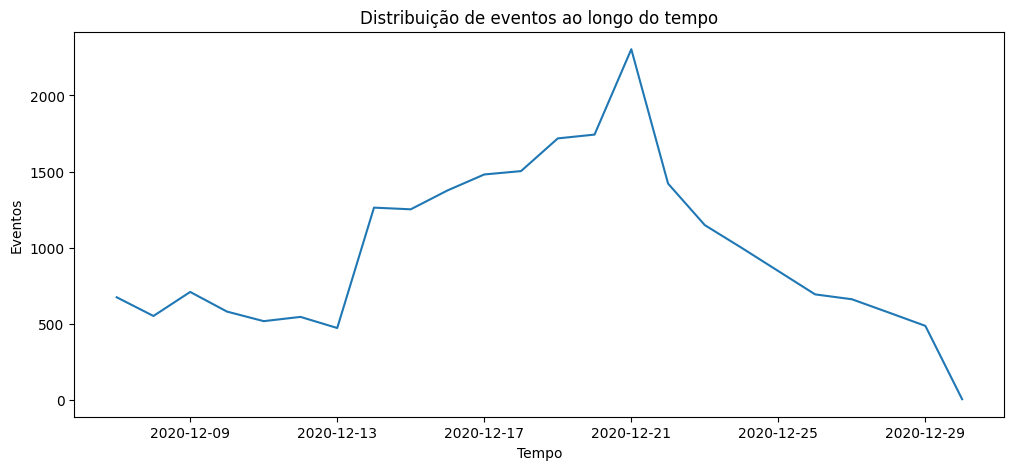

In [19]:

# Vamos analisar a distribuição ao longo do tempo
event_ab_correct = event_final_ab[event_final_ab['user_id'].isin(participant_ab_eu['user_id'])].copy()
event_ab_correct['event_day'] = event_ab_correct['event_dt'].dt.date
event_per_day = event_ab_correct.groupby('event_day')['event_name'].count()

event_per_day.plot(figsize=(12, 5))
plt.title('Distribuição de eventos ao longo do tempo')
plt.xlabel('Tempo')
plt.ylabel('Eventos')
plt.show()





<div class="alert alert-block alert-warning">

O seu gráfico de eventos diários está claro e usa apenas os participantes da UE. Vale a pena mencionar explicitamente duas particularidades dos dados. Primeiro, a linha vai direto de 24/12 para 26/12 porque 25/12 não tem nenhum evento, então confirme se esse dia realmente está ausente, mencione isso e considere usar `marker='o'` para tornar a lacuna visível. Segundo, os eventos disparam em 14/12 (de aproximadamente 470 para aproximadamente 1.260) e nada explica isso ainda. Contar os cadastros por dia e por grupo com `first_date` mostraria se o salto vem de usuários entrando no teste.

</div>

In [20]:

print(event_final_ab['event_dt'].min())
print(event_final_ab['event_dt'].max())


2020-12-07 00:00:33
2020-12-30 23:36:33


O gráfico apresenta uma tendência geral de crescimento de 07/12 até 21/12, onde ocorre o pico de número de eventos e com oscilações no meio, especialmente entre os dias 14/12 e 18 ou 19/12. Esse crescimento pode ser por causa das compras natalinas características desta época do ano. Após o dia 21/12 até 29/12 há uma queda acentuada, hipoteticamente, pelo período pós-natal, terminando com uma queda brusca no final em 30/12. Apesar dos dados incompletos deste dia (a coleta termina antes do esperado), a queda acentuada acontecia desde antes, talvez desde manhã, o que mostra uma queda natural de final de evento. Diante disso, optamos por manter todo o período de coleta (07/12 a 30/12), pois a perda do último dia é mínima e não compromete a análise.

<div class="alert alert-block alert-warning">

Sua descrição da curva (crescimento até 21/12, um pico e depois uma queda) corresponde ao gráfico, e rotular a explicação do período pós-Natal como uma hipótese é uma boa prática. Algumas afirmações contradizem os seus próprios resultados. Você diz que a perda de 30/12 é 'mínima', mas o seu gráfico cai para quase zero nesse dia e uma verificação posterior mostra 89 eventos contra cerca de 10.000 em 29/12. Você também remove 30/12 mais adiante, então o notebook diz duas coisas opostas sobre esse dia. 'Talvez desde a manhã' é uma especulação que contagens por hora poderiam testar. A queda após 21/12 reflete principalmente o fim de novos cadastros, com o período pós-Natal e a promoção de 25/12 como possíveis fatores adicionais. Sugestão de redação: 'Os dados terminam em 30/12, enquanto o teste estava planejado até 01/01, o que é uma limitação de cobertura. 30/12 está incompleto (pouquíssimos eventos), portanto é excluído. A queda após 21/12 reflete principalmente o fim de novos cadastros.'

</div>

In [21]:
# Verificando se existe usuários duplicados na tabela já filtrada para o teste A/B
duplicated_id_filtered = participant_ab_eu.duplicated(subset=['user_id'])
print(duplicated_id_filtered.sum())


0


In [22]:

# Vamos verificar se o número de purchase e de details são iguais
# 1. Conta os details não-nulos nas linhas de purchase
details_na_count = event_ab_correct[event_ab_correct['event_name'] == 'purchase']['details'].notna().sum()
print(f"Contagem de details não-nulos entre as linhas de purchase: {details_na_count}")

# 2. Conta o total de linhas com o evento purchase
purchase_total_count = event_ab_correct[event_ab_correct['event_name'] == 'purchase'].shape[0]
print(f"Total de linhas de purchase: {purchase_total_count}")

# 3. Verifica quais eventos possuem details preenchidos
values = event_ab_correct[event_ab_correct['details'].notna()]['event_name'].unique()
print("Eventos com details preenchidos:", values)




Contagem de details não-nulos entre as linhas de purchase: 3079
Total de linhas de purchase: 3079
Eventos com details preenchidos: ['purchase']


Até aqui fiz a limpeza dos dados e está ok para começar a analise. Percebi que o número de purchase é igual a de details e isso bate com o que é esperado, já que details só preenche as linhas quando há purchase. Ou seja, os nulos contido em details é esperado e não um problema de qualidade dos dados. Mesmo após o valor absoluto ter mudado (20699 em vez de 363447 dos dados brutos), a conclusão ainda é a mesma.

<div class="alert alert-block alert-warning">

Sua conclusão está correta: `details` é preenchido apenas para compras (3.079 valores não nulos para 3.079 compras), então os valores ausentes são esperados e não representam um problema de qualidade. No entanto, o número '20699 em vez de 363447' não aparece em nenhum lugar do seu notebook, pois pertence a uma população mais antiga. Calcule o valor para a tabela atual, apenas da UE, por exemplo `event_ab_correct[event_ab_correct['event_name'] != 'purchase']['details'].isna().sum()`, e cite esse valor para que o texto corresponda aos seus outputs.

</div>

In [23]:

# Vamos contar quantos nunique() == 2, ou seja quantos usuários estão nos dois grupos
# 1. Conta quantos grupos únicos cada usuário possui na tabela de participantes
user_group_counts = participant_ab_eu.groupby('user_id')['group'].nunique()

# 2. Filtra os usuários que aparecem em 2 grupos diferentes (sobreposição)
overlapping_users = user_group_counts[user_group_counts == 2]

# 3. Exibe a quantidade total de usuários com problema
print(f"Número de usuários com sobreposição entre os grupos: {overlapping_users.count()}")



Número de usuários com sobreposição entre os grupos: 0


In [24]:
# Filtrando os usuários que pertencem ao grupo de teste correto
users_ab_correct = users_final_ab[users_final_ab['user_id'].isin(participant_ab_eu['user_id'])].copy()
print(users_ab_correct.shape[0])
print(participant_ab_eu['user_id'].nunique())
print(users_ab_correct['user_id'].duplicated().sum())
print(users_final_ab['user_id'].duplicated().sum())


3481
3481
0
0


In [25]:

# vamos começar o filtro pela data
event_ab_first_date = users_ab_correct.merge(event_ab_correct, on='user_id')
event_ab_first_date['days_from_registration']= event_ab_first_date['event_dt'] - event_ab_first_date['first_date']

event_ab_14d = event_ab_first_date[event_ab_first_date['days_from_registration'] <= pd.Timedelta(days=14)]
invalid_days_count = event_ab_first_date[event_ab_first_date['days_from_registration'] < pd.Timedelta(days=0)].shape[0]
event_group_14d = event_ab_14d.merge(participant_ab_eu, on='user_id', how='left')
users_unique_14d = event_group_14d.groupby(['event_name','group'])['user_id'].nunique().unstack()


print(users_unique_14d)
print(invalid_days_count)





group            A    B
event_name             
login         2604  876
product_cart   782  244
product_page  1685  493
purchase       833  249
0


<div class="alert alert-block alert-success">

Este bloco está bem construído. Você calcula o tempo entre o cadastro e cada evento, aplica a janela de 14 dias, verifica se não há eventos antes do registro (0 casos) e constrói contagens de usuários únicos por etapa do funil e por grupo na população apenas da UE. É uma base sólida para as taxas de conversão e os testes z.

</div>

In [26]:
# 1. Para o DataFrame original (event_ab_correct)
line_before = event_ab_correct[event_ab_correct['event_name'] == 'purchase'].shape[0]
unique_before = event_ab_correct[event_ab_correct['event_name'] == 'purchase']['user_id'].nunique()

# 2. Para o DataFrame filtrado (event_ab_14d)
line_after = event_ab_14d[event_ab_14d['event_name'] == 'purchase'].shape[0]
unique_after = event_ab_14d[event_ab_14d['event_name'] == 'purchase']['user_id'].nunique()

# Exibindo os resultados
print(f"Antes dos 14 dias -> Total de linhas (eventos): {line_before} | Usuários únicos: {unique_before}")
print(f"Depois dos 14 dias -> Total de linhas (eventos): {line_after} | Usuários únicos: {unique_after}")



Antes dos 14 dias -> Total de linhas (eventos): 3079 | Usuários únicos: 1082
Depois dos 14 dias -> Total de linhas (eventos): 2998 | Usuários únicos: 1082


Pelos cálculos acima, os usuários fizeram compras tanto dentro quanto fora da janela de 14 dias, ou seja, o filtro de 14 dias reduz o número de eventos considerados (removendo ruído de ações tardias), mas não altera a contagem de usuários únicos por etapa do funil. 
O funil que estamos assumindo neste projeto (login/product_page/product_cart/purchase) representa o caminho esperado, mas ao que parece não é o que sempre acontece na realidade. Uma das possibilidades disto acontecer é que alguns usuários compram direto, sem passar pelo carrinho, por exemplo, algum botão checkout que não passa pelo carrinho de compra ou falha no rastreamento do evento product_cart (deixou por algum motivo de rastrear os produtos do carrinho ou por causa da falta de carrinho persistente/sessões).



<div class="alert alert-block alert-warning">

Seu argumento de que o funil não é estritamente sequencial é razoável, e a anomalia é real: 833 compradores vs 782 usuários com carrinho no grupo A, e 249 vs 244 no grupo B. Ainda restam dois pontos em aberto. Primeiro, você diz que o filtro de 14 dias não altera o número de usuários únicos por etapa, mas você verificou apenas as compras (1.082 antes e depois). O seu próprio output mostra 877 participantes no grupo B, mas 876 usuários com login na janela, então verifique todas as etapas ou limite a afirmação às compras. Segundo, o bypass do checkout e a falha de tracking ainda são hipóteses. Você pode testar a primeira diretamente: `buyers = set(event_ab_14d.loc[event_ab_14d['event_name']=='purchase','user_id'])`, `cart_users = set(event_ab_14d.loc[event_ab_14d['event_name']=='product_cart','user_id'])`, e então `print(len(buyers - cart_users))` mostra os compradores sem nenhum evento de carrinho.

</div>

In [27]:
# Vamos verificar se o número de eventos dos usuários é distribuído igualmente entre A e B
user_event_count = event_group_14d.groupby(['user_id', 'group'])['event_name'].count()
user_event_count = user_event_count.reset_index()
user_event_count.head()

user_event_group_filtered = user_event_count[user_event_count['group'].notna()]

group_event_stats = user_event_group_filtered.groupby('group')['event_name'].describe()
group_event_stats.head()



,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,2604.0,6.619432,3.667608,1.0,4.0,6.0,9.0,24.0
B,877.0,5.376283,3.228340,1.0,3.0,4.0,7.0,24.0


Além do desbalanceamento no tamanho total das amostras, a diferença na distribuição de eventos por usuário — com o Grupo A registrando uma média superior (6,61 eventos) em comparação ao Grupo B (5,37) — traz um impacto crítico para a interpretação das taxas de conversão. Esse comportamento indica que os usuários do Grupo A não são apenas mais numerosos, mas também inerentemente mais ativos e engajados na plataforma. Essa assimetria no nível de atividade pode distorcer as métricas do funil, uma vez que usuários mais ativos possuem maior probabilidade de transitar entre as etapas (como de visualização para o carrinho e compra). Consequentemente, qualquer variação observada nas taxas de conversão pode ser reflexo dessa diferença prévia de comportamento e engajamento, e não necessariamente do efeito real da mudança testada, reforçando que os resultados do teste A/B estão comprometidos e devem ser interpretados com extrema cautela.

<div class="alert alert-block alert-warning">

Você encontrou uma diferença real no número de eventos por usuário (6,61 vs 5,37), o que é uma descoberta valiosa. Porém, a interpretação vai além do que os dados mostram. "Inerentemente mais ativos e engajados" não foi demonstrado: o grupo B pode ter menos eventos por causa do novo recomendador, ou porque seus usuários se cadastraram mais tarde e tiveram menos tempo para agir. Apresente essas possibilidades como hipóteses e verifique-as, por exemplo comparando as datas de cadastro por grupo. "Impacto crítico" e "comprometido" também são expressões fortes sem um teste de significância, então um teste de Mann-Whitney (`scipy.stats.mannwhitneyu`) ou uma redação mais branda seria mais adequado. Por fim, tamanhos de grupo diferentes e médias por usuário diferentes são dois problemas separados, então evite misturá-los no mesmo argumento.

</div>

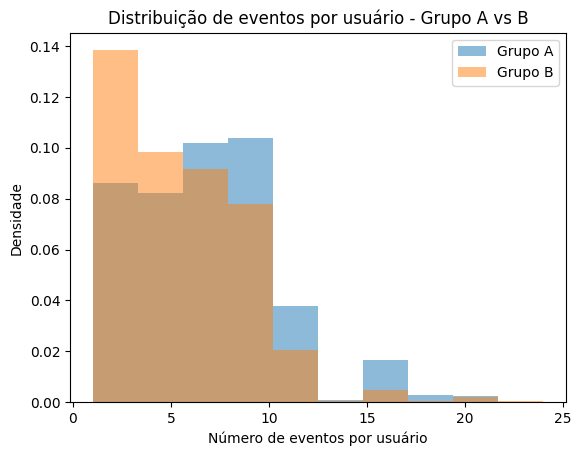

In [28]:
#Vamos criar um histograma para visualizar os resultados acima

line_a = user_event_group_filtered[user_event_group_filtered['group']=='A']['event_name']
line_b = user_event_group_filtered[user_event_group_filtered['group']=='B']['event_name']

plt.hist(line_a, alpha=0.5, density= True, label='Grupo A')
plt.hist(line_b, alpha=0.5, density=True, label='Grupo B')
plt.xlabel('Número de eventos por usuário')
plt.ylabel('Densidade')
plt.title('Distribuição de eventos por usuário - Grupo A vs B')
plt.legend()
plt.show()


A análise estatística descritiva e a visualização das distribuições revelaram diferenças importantes no comportamento de engajamento entre os dois grupos. Em termos de volume médio, o Grupo A apresentou uma média superior (6.61 eventos por usuário) em comparação ao Grupo B (5.37 eventos). Essa assimetria visualiza-se claramente no histograma com densidade normalizada: o Grupo B demonstra uma concentração maior em faixas mais baixas de eventos (especialmente entre 1 e 5), enquanto o Grupo A distribui sua densidade de maneira diferente em faixas intermediárias. Embora variações no engajamento possam ocorrer, essa assimetria na distribuição e no volume médio reforça o desbalanceamento estrutural previamente observado entre os grupos, indicando que a disparidade no comportamento dos usuários deve ser considerada com cautela antes de avançar para as conclusões definitivas dos testes estatísticos de conversão.

group            A      B
event_dt                 
2020-12-07   318.0  356.0
2020-12-08   313.0  238.0
2020-12-09   371.0  338.0
2020-12-10   331.0  249.0
2020-12-11   356.0  161.0
2020-12-12   346.0  199.0
2020-12-13   308.0  164.0
2020-12-14  1015.0  248.0
2020-12-15  1030.0  222.0
2020-12-16  1007.0  369.0
2020-12-17  1200.0  281.0
2020-12-18  1244.0  259.0
2020-12-19  1430.0  288.0
2020-12-20  1434.0  309.0
2020-12-21  1903.0  401.0
2020-12-22  1236.0  185.0
2020-12-23   959.0  189.0
2020-12-24   850.0  149.0
2020-12-26   580.0  113.0
2020-12-27   547.0  114.0
2020-12-28   479.0   95.0
2020-12-29   413.0   73.0
2020-12-30     NaN    4.0


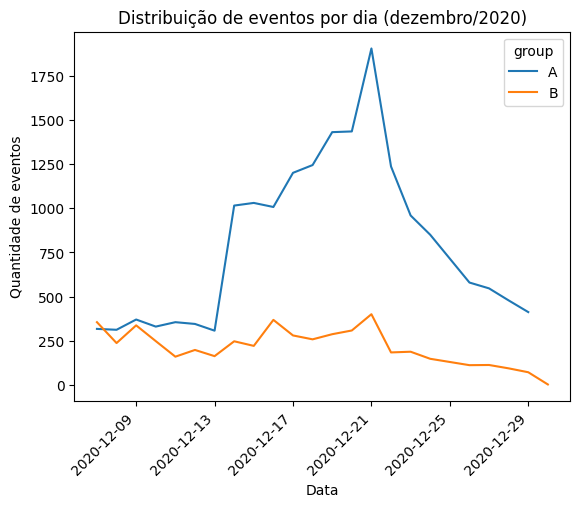

In [29]:
# Vamos montar um gráfico para melhor visualizar a distribuição dos eventos por dia
event_group_full = event_ab_correct.merge(participant_ab_eu, on='user_id', how='left')
event_per_day = event_group_full['event_dt'].dt.date
events_by_date_group = event_group_full.groupby([event_per_day, event_group_full['group']])['user_id'].count().unstack()

print(events_by_date_group)
events_by_date_group.plot()
plt.title('Distribuição de eventos por dia (dezembro/2020)')
plt.xlabel('Data')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Quantidade de eventos')
plt.show()


A análise da distribuição diária de eventos ao longo de dezembro de 2020 evidencia uma assimetria marcante no comportamento temporal entre os grupos. Enquanto o Grupo B manteve um volume de eventos relativamente baixo, estável e com pequenas flutuações ao longo de todo o período, o Grupo A apresentou um crescimento abrupto e expressivo a partir do dia 14/12, culminando em um pico acentuado próximo ao dia 21/12 (ultrapassando 2.000 eventos diários) antes de entrar em declínio. Essa discrepância temporal reforça as diferenças entre as amostragens analisadas, demonstrando que os grupos não foram expostos de forma homogênea ao longo do tempo, o que compromete a comparabilidade direta dos dados e a validade das conclusões do teste A/B.

<div class="alert alert-block alert-warning">

Esta descrição captura a ideia principal (A sobe bruscamente a partir de 14/12 e depois diminui), mas vários detalhes não correspondem à sua tabela e ao seu gráfico. A atinge o pico de 1.903 eventos em 21/12, e não 'acima de 2.000'. B não é 'estável': varia de 73 a 401 eventos, atinge o pico em 21/12 e diminui depois, seguindo a mesma forma geral de A, porém com um volume menor, e até começa acima de A nos primeiros dias. Essas são contagens brutas de grupos de tamanhos muito diferentes (2.604 vs 877), portanto o tamanho por si só explica grande parte da diferença, e afirmar que os grupos não foram expostos de forma homogênea e que a validade está comprometida é prematuro. Para entender por que A dispara em 14/12, compare os cadastros por dia e grupo: `users_ab_correct.merge(participant_ab_eu, on='user_id').groupby([users_ab_correct['first_date'].dt.date, 'group']).size().unstack()`. Sua análise per capita posterior mostra os grupos muito mais próximos em formato, então conecte as duas análises.

</div>

In [30]:


# Vamos analisar o por quê da queda nos últimos dias de evento
print(event_final_ab['event_dt'].min())
print(event_final_ab['event_dt'].max())




2020-12-07 00:00:33
2020-12-30 23:36:33


A análise temporal revelou que a coleta de eventos encerra-se em 30/12/2020, enquanto o teste estava planejado até 01/01/2021, configurando uma limitação de cobertura. A redução no volume diário de eventos observada após o dia 21/12 reflete o término natural das inscrições de novos usuários, e não uma falha de registro. No entanto, como os logs param em 30/12, os participantes cadastrados após 15/12 não dispuseram da janela completa de 14 dias de acompanhamento. Essa restrição temporal, combinada com as diferenças de engajamento e com a diferença amostral no início, deve ser ponderada na análise, apontando que o teste apresenta limitações operacionais importantes que exigem cautela na interpretação de seus resultados.

<div class="alert alert-block alert-success">

Bom trabalho ao relatar a descoberta real: os logs terminam em 30/12, enquanto o teste estava planejado até 01/01, o que é uma limitação de cobertura. Você atribui a queda após 21/12 ao fim das inscrições (um efeito de coorte) em vez de uma falha de logging, e relaciona o ponto de corte aos usuários que se inscreveram após 15/12 e não têm uma janela completa de 14 dias.

</div>

In [31]:
# Investigando a queda do final do período dos dados coletados

event_filtered = event_final_ab[event_final_ab['event_dt'] >= '2020-12-27']
event_day = event_filtered['event_dt'].dt.date
event_grouped = event_filtered.groupby(event_day)['event_dt'].count()

print(event_grouped)



event_dt
2020-12-27    12420
2020-12-28    11014
2020-12-29    10146
2020-12-30       89
Name: event_dt, dtype: int64


A análise dos registros diários do período de queda no final dos dados entre 27/12 e 30/12 evidencia uma queda considerável e abrupta no volume total de eventos: o tráfego diário recua de aproximadamente 12420 no dia 27 para 10146 no dia 29/12, despencando de forma drástica para apenas 89 eventos no dia 30/12. Esse comportamento indica que no dia 30/12 é um registro incompleto ou parcial da coleta e não uma queda real do engajamento.  

In [32]:
# Como o dia 30-12-2020 está com uma diferença muito significativa em relação ao restante do dias, vamos retirá-lo
event_data = event_group_full[(event_group_full['event_dt'] < '2020-12-30')].copy()

print(event_data)


                user_id            event_dt event_name  details   event_day  \
0      831887FE7F2D6CBA 2020-12-07 06:50:29   purchase     4.99  2020-12-07   
1      3C5DD0288AC4FE23 2020-12-07 19:42:40   purchase     4.99  2020-12-07   
2      49EA242586C87836 2020-12-07 06:31:24   purchase    99.99  2020-12-07   
3      2B06EB547B7AAD08 2020-12-07 21:36:38   purchase     4.99  2020-12-07   
4      A640F31CAC7823A6 2020-12-07 18:48:26   purchase     4.99  2020-12-07   
...                 ...                 ...        ...      ...         ...   
22667  36EDA624DB7B7F90 2020-12-29 20:54:25      login      NaN  2020-12-29   
22668  E5589EAE02ACD150 2020-12-29 22:17:08      login      NaN  2020-12-29   
22669  D21F0D4FDCD82DB2 2020-12-29 02:17:00      login      NaN  2020-12-29   
22670  96BDD55846D1F7F6 2020-12-29 16:53:42      login      NaN  2020-12-29   
22671  553BAE96C6EB6240 2020-12-29 14:09:14      login      NaN  2020-12-29   

      group                  ab_test  
0         A 

In [33]:
# Vamos verificar se deu certo
print(event_data['event_dt'].min())
print(event_data['event_dt'].max())



2020-12-07 00:05:57
2020-12-29 23:38:29


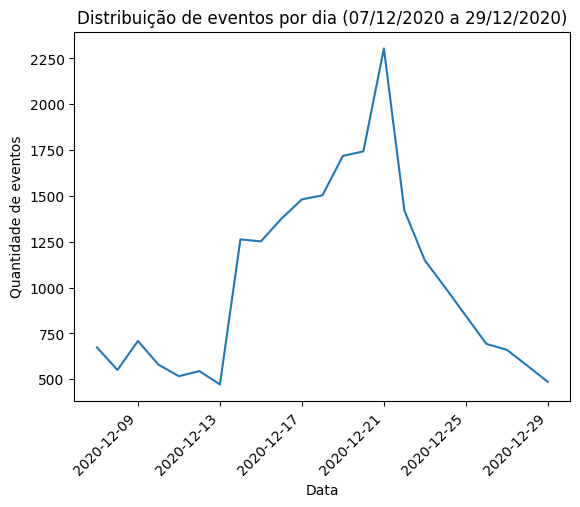

In [34]:
# Como deu certo, vamos refazer o gráfico com os dados já filtrados para os dias 07/12 a 29/12

event_per_day = event_data['event_dt'].dt.date
event_per_day_filtered = event_data.groupby(event_per_day)['event_name'].count()


event_per_day_filtered.plot()
plt.title('Distribuição de eventos por dia (07/12/2020 a 29/12/2020)')
plt.xlabel('Data')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Quantidade de eventos')
plt.show()


Ao analisar a distribuição diária sem o dia incompleto de 30/12, fica claro que a quantidade de eventos não foi constante ao longo do teste. O volume manteve-se baixo na primeira semana (entre 500 e 750 eventos diários), deu um salto repentino a partir de 14/12 e atingiu um pico próximo de 2500 eventos em 21/12 — data limite de entrada de novos usuários. Depois disso, como deixaram de entrar novos participantes e a amostragem não avançou até final do período conforme previsto (01/01), os eventos caíram gradualmente até o fim do período registado.

<div class="alert alert-block alert-warning">

Relacionar o pico com 21/12, o fim das inscrições, é uma interpretação sólida. Alguns números não correspondem ao seu gráfico: o pico é de cerca de 2.300 eventos (e não cerca de 2.500), a primeira semana fica em torno de 470-710 (e não 500-750), e a queda após 21/12 é acentuada no primeiro dia (de cerca de 2.300 para cerca de 1.400) antes de se tornar gradual. A frase sobre a amostragem não avançar até o fim do período é difícil de entender. Diga, em vez disso, que os logs terminam em 30/12, antes do dia 01/01 planejado.

</div>

In [35]:
# 1. Obter o total de usuários em cada grupo (ex: contando a partir do DataFrame de usuários válidos)
shape_groups = participant_ab_eu['group'].value_counts()
total_a = shape_groups['A']
total_b = shape_groups['B']

# 2. Calcular a proporção diária de usuários ativos em relação ao total de cada grupo
event_data['event_day'] =  event_data['event_dt'].dt.date
events_per_day_group = event_data.groupby(['event_day', 'group'])['user_id'].nunique().unstack()

events_per_day_group['ratio_A'] = events_per_day_group['A'] / total_a
events_per_day_group['ratio_B'] = events_per_day_group['B'] / total_b

# 3. Agora sim, a razão per capita entre os grupos (ou plotar ambas as colunas para ver a evolução)
events_per_day_group['ratio_per_capita_A_B'] = events_per_day_group['ratio_A'] / events_per_day_group['ratio_B']



events_per_day_group.head()



group,A,B,ratio_A,ratio_B,ratio_per_capita_A_B
event_day,,,,,
2020-12-07,148,163,0.056836,0.185861,0.305797
2020-12-08,147,114,0.056452,0.129989,0.434281
2020-12-09,171,161,0.065668,0.183580,0.357708
2020-12-10,156,124,0.059908,0.141391,0.423703
2020-12-11,176,84,0.067588,0.095781,0.705654


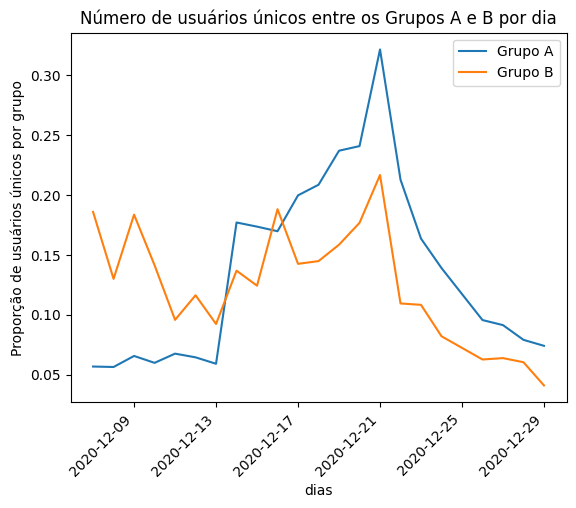

In [36]:
plt.plot(events_per_day_group['ratio_A'], label='Grupo A')
plt.plot(events_per_day_group['ratio_B'], label='Grupo B')
plt.title('Número de usuários únicos entre os Grupos A e B por dia')
plt.xlabel('dias')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Proporção de usuários únicos por grupo')
plt.legend()
plt.show()


Ao dividir os usuários ativos diários pelo total de cada grupo, eliminamos o véis de tamanho e vemos que os grupos têm uma dinâmica significativa. 07/12 a 13/12: O Grupo B começa com uma proporção maior de usuários ativos. 14/12 a 21/12: Ambos crescem juntos até atingirem o pico no dia 21/12 (fim dos cadastros), onde o Grupo A chega a aproximandamente 32% e o B a aproximadamente 22%. Após 21/12: Sem novos cadastros, ambos caem de forma paralela até o fim dos dados em 29/12.

<div class="alert alert-block alert-warning">

Normalizar pelo tamanho do grupo é a ideia certa, e seus picos de cerca de 32% (A) e 22% (B) condizem com o gráfico. Ainda há alguns detalhes a ajustar. 'Os grupos têm uma dinâmica significativa' não diz nada de específico, então diga se os grupos se comportam de forma parecida ou diferente. 'Ambos crescem juntos' entre 14/12 e 21/12 não é preciso: A salta para cerca de 17% em 14/12, enquanto B oscila entre cerca de 9% e 19% até 17/12 e só então sobe. Apresente os números reais da primeira semana (cerca de 19% de B ativos em 07/12 contra cerca de 6% de A) e diga explicitamente que essa diferença inicial é uma particularidade a ser considerada antes de interpretar os resultados do teste A/B. Observe também que dividir pelo tamanho total do grupo remove o efeito do tamanho, mas não o efeito do momento de cadastro, então 'eliminou o viés' é uma afirmação forte demais. Erros de digitação: 'véis' deveria ser 'viés' e 'aproximandamente' deveria ser 'aproximadamente'.

</div>

In [37]:

# Vamos verificar se correspondem os participantes esperados (6000) com o real dos dados
total_participants = participant_ab_correct['user_id'].nunique()
print(total_participants)

# Vamos verifica quantos usuários do teste correto NÃO possuem nenhum evento registrado
usuarios_sem_eventos = ~users_ab_correct['user_id'].isin(event_ab_correct['user_id'])
total_sem_eventos = usuarios_sem_eventos.sum()

print(f"Total de participantes no teste correto: {users_ab_correct.shape[0]}")
print(f"Usuários cadastrados que nunca geraram eventos: {total_sem_eventos}")



3675
Total de participantes no teste correto: 3481
Usuários cadastrados que nunca geraram eventos: 0


O total de participantes válidos no teste A/B foi de 3.675 (com 3.481 registros únicos avaliados), valor inferior aos 6.000 previstos no planejamento inicial do projeto. Como todos os participantes registrados possuem pelo menos um evento associado (sendo o login o ponto de partida comum), a divergência em relação ao tamanho planejado indica que houve menos adesão que o planejado.

In [38]:

# verificando os 15% da UE
participant_region = users_final_ab.merge(participant_ab_correct, on='user_id')

region_counts_test = participant_region['region'].value_counts()
print(region_counts_test)

eu_participants = (region_counts_test['EU']/region_counts['EU']) * 100

print(f"porcentagem usuários EU: {eu_participants:.2f}")




EU           3481
N.America     119
APAC           45
CIS            30
Name: region, dtype: int64
porcentagem usuários EU: 8.02


O esperado para este teste era que o público da Europa (EU) representasse cerca de 15% dos novos usuários, mas os cálculos acima mostram que o valor real ficou em 8,02%. Isso sugere que a base de usuários válidos para o experimento era menor do que o planejado — o que também se reflete no número total de participantes, que ficou em 3.675 em vez dos 6.000 esperados. Essa diferença reforça que os filtros de segmentação (como o recorte regional e as regras de entrada do experimento) limitaram significativamente o tamanho da amostra logo no início.

<div class="alert alert-block alert-warning">

Comparar os 8,02% com os 15% planejados é a verificação correta. A explicação precisa de ajustes. Seus filtros foram aplicados depois que o teste foi executado, portanto não podem ter 'limitado a amostra desde o início'. Apresente isso como um desvio em relação ao desenho do teste: o teste alcançou uma parcela menor de novos usuários da UE do que o planejado. O texto também repete a confusão de populações da verificação anterior da contagem de participantes: os 3.675 incluem os 194 participantes não pertencentes à UE que você excluiu, então compare seus 3.481 participantes da UE com os 6.000 planejados. Por fim, relacione a amostra pequena, especialmente o grupo B, muito menor (877 vs 2.604), ao poder estatístico para detectar um aumento de 10%.

</div>

In [39]:
#Vamos recalcular as taxas de conversão para users_unique_14d

login_to_pageview_rate_14d = (users_unique_14d.loc['product_page']/users_unique_14d.loc['login'])*100
pageview_to_cart_rate_14d = (users_unique_14d.loc['product_cart']/users_unique_14d.loc['product_page'])*100
login_to_purchase_rate_14d = (users_unique_14d.loc['purchase']/users_unique_14d.loc['login'])*100

print(f"Conversão entre login e página de produto A:{login_to_pageview_rate_14d['A']:.2f}")
print(f"Conversão entre login e página de produto B: {login_to_pageview_rate_14d['B']:.2f}")
print(f"Conversão entre página de produto e carrinhos de compra A: {pageview_to_cart_rate_14d['A']:.2f}")
print(f"Conversão entre página de produto e carrinhos de compra B: {pageview_to_cart_rate_14d['B']:.2f}")
print(f"Conversão entre login e compras efetivas A: {login_to_purchase_rate_14d['A']:.2f}")
print(f"Conversão entre login e compras efetivas B: {login_to_purchase_rate_14d['B']:.2f}")


Conversão entre login e página de produto A:64.71
Conversão entre login e página de produto B: 56.28
Conversão entre página de produto e carrinhos de compra A: 46.41
Conversão entre página de produto e carrinhos de compra B: 49.49
Conversão entre login e compras efetivas A: 31.99
Conversão entre login e compras efetivas B: 28.42


Ao substituir a etapa que dava acima de 100% (product_cart - purchase) pela conversão direta desde o início do funil (login - purchase), todas as taxas passaram a operar dentro do intervalo lógico esperado (entre 0% e 100%), resolvendo a anomalia apontada anteriormente. Comparando o desempenho entre os grupos na janela de 14 dias, observa-se que o Grupo B teve um desempenho inferior ao Grupo A tanto na transição de login para product_page (56,28% contra 64,71%) quanto na taxa de conversão geral de login para purchase (28,42% contra 31,99%), superando o controle apenas na etapa intermediária de product_page para product_cart (49,49% frente a 46,41%).

In [40]:
date_cortes_14d = pd.to_datetime('2020-12-15')
users_ab_correct.loc[:,'first_date'] = pd.to_datetime(users_ab_correct['first_date'])
users_no_cut_14d_complete = users_ab_correct[users_ab_correct['first_date'] > date_cortes_14d]

users_affected = users_no_cut_14d_complete.shape[0]
total_general = users_ab_correct.shape[0]
affected_percentual = (users_affected/total_general) *100

print(f"Usuários com janela incompleta (cadastrados após 15/12): {users_affected} de {total_general}")
print(f"Representa {affected_percentual:.2f}% do total de participantes do teste.")


Usuários com janela incompleta (cadastrados após 15/12): 1821 de 3481
Representa 52.31% do total de participantes do teste.


<div class="alert alert-block alert-success">

Sua lógica está correta: com dados utilizáveis até 29/12, apenas os usuários que se registraram em 15/12 ou antes têm 14 dias completos. O resultado (1.821 de 3.481, ou 52,31%) está claramente identificado e se conecta à limitação de cobertura que você identificou. Opcionalmente, divida essa contagem por grupo, já que o momento de cadastro parecia diferente entre A e B.

</div>

Os números mostram que 1821 de 3481 usuários (52,3%) se cadastraram depois de 15/12 e por isso não têm os 14 dias completos de análise até 29/12, um volume bem relevante, o que mostra mais uma limitação amostral. Esta limitação deve ser considerada ao interpretar os resultados do teste, uma vez que mais da metade da amostra não tem a janela completa.

Vamos verificar o z-test para comparar as proporções
H0 : A proporção de usuários que avançam de login para product_page no grupo B é menor ou igual que no grupo A.
H1: A proporção de usuários que avançam de login para product_page no grupo B é maior que no grupo A.
H0: A proporção de transição entre product_page e product_cart no grupo B é menor ou igual que no grupo A.
H1: A proporção de transição entre product_page e product_cart no grupo B é maior que no grupo A.
H0: A proporção de transição entre product_cart e purchase no grupo B é menor ou igual que no grupo A.
H1: A proporção de transição entre product_cart e purchase no grupo B é maior que no grupo A. 


<div class="alert alert-block alert-warning">

Suas hipóteses estão claramente formuladas e correspondem aos testes unilaterais que você executa. Dois pequenos ajustes ajudariam. O terceiro par ainda descreve a transição entre product_cart e purchase, enquanto o teste que você executa compara compradores em relação a todos os usuários que fizeram login (login para purchase). O teste de carrinho para compra que você executa mais adiante não tem nenhuma hipótese escrita. Rotule cada par com a sua etapa do funil e alinhe-o ao teste realmente realizado. Além disso, acrescente uma frase dizendo que esses testes verificam apenas se B é melhor que A, e que a meta de 10% é verificada separadamente, comparando o lift observado com 10%.

</div>

In [41]:
login_a = users_unique_14d.loc[('login','A')]
login_b = users_unique_14d.loc[('login', 'B')]
page_a = users_unique_14d.loc[('product_page', 'A')]
page_b = users_unique_14d.loc[('product_page', 'B')]
cart_a = users_unique_14d.loc[('product_cart', 'A')]
cart_b = users_unique_14d.loc[('product_cart', 'B')]
purchase_a = users_unique_14d.loc[('purchase', 'A')]
purchase_b = users_unique_14d.loc[('purchase', 'B')]

# A divisão de alpha é por 3 porque estamos testando 3 etapas, pois cada teste adicional aumenta a chance de "falso positivo" por acaso e o teste de Bonferroni compensa isso dividindo alpha pelo num de comparações feitas.
alpha = 0.05 / 3 

print("Etapa 1: login -> product_page")
stat_1, p_value_1 = proportions_ztest(count=[page_b, page_a], nobs=[login_b, login_a], alternative='larger')
print(f"Valor de stat e p-value: {stat_1:.4f}, {p_value_1:.4f}")

if p_value_1 < alpha:
    print("Rejeitamos H0: O grupo B apresenta melhoria estatistica relevante.")
else:
    print("Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.")

print("Etapa 2: product_page -> product_cart")
stat_2, p_value_2 = proportions_ztest(count=[cart_b, cart_a], nobs=[page_b, page_a], alternative='larger')
print(f"Valor de stat e p-value: {stat_2:.4f}, {p_value_2:.4f}")

if p_value_2 < alpha:
    print("Rejeitamos H0: O grupo B apresenta melhoria estatistica relevante.")
else:
    print("Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.")

print("Etapa 3: login - purchase")
stat_3, p_value_3 = proportions_ztest(count=[purchase_b, purchase_a], nobs=[login_b, login_a], alternative='larger')
print(f"Valor de stat e p-value: {stat_3}, {p_value_3}")

# Verifica se a diferença é estatisticamente significativa
if p_value_3 < alpha:
    print("Rejeitamos H0: O grupo B apresenta melhoria estatistica relevante.")
else:
    print("Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.")

print(f"Grupo A - Carrinho: {cart_a}, Compras: {purchase_a}")
print(f"Grupo B - Carrinho: {cart_b}, Compras: {purchase_b}")
print(f"Grupo A - Total: {login_a}")
print(f"Grupo B - Total: {login_b}")


Etapa 1: login -> product_page
Valor de stat e p-value: -4.4600, 1.0000
Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.
Etapa 2: product_page -> product_cart
Valor de stat e p-value: 1.2064, 0.1138
Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.
Etapa 3: login - purchase
Valor de stat e p-value: -1.971666704350226, 0.9756761665247878
Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.
Grupo A - Carrinho: 782, Compras: 833
Grupo B - Carrinho: 244, Compras: 249
Grupo A - Total: 2604
Grupo B - Total: 876


<div class="alert alert-block alert-warning">

Bom progresso: o terceiro teste agora está rotulado como login para compra e usa as contagens de login como denominadores, o que corresponde aos 28,42% e 31,99% que você informa mais adiante, e sua explicação sobre Bonferroni está clara. Algumas melhorias opcionais: a explicação diz que o alpha é dividido por 3, mas você executa um quarto teste (carrinho para compra) mais adiante, então use `0.05 / 4` se os quatro testes pertencerem à mesma família. A mensagem 'B shows a relevant statistical improvement' pode ser lida como se a meta de 10% tivesse sido atingida, então algo como 'B is statistically higher than A (alpha = ...)' é mais preciso. No passo 1, z = -4.46 significa que B é significativamente pior, mas o teste unilateral 'larger' apenas informa que não há evidência de que B seja melhor, então adicione uma observação para estatísticas negativas grandes ou execute `alternative='smaller'` nesse passo. Além disso, rotule as contagens de login como 'users with login' em vez de 'Total'.

</div>

In [42]:

# Vamos calcular a taxa de conversão dos grupos A e B para etapa 1
tax_a_step_1 = (page_a/login_a)*100
tax_b_step_1 = (page_b/login_b)*100
lift_login_page_1 = ((tax_b_step_1-tax_a_step_1)/tax_a_step_1)*100

print(f"Taxa de conversão A (login → página): {tax_a_step_1:.2f}%")
print(f"Taxa de conversão B (login → página): {tax_b_step_1:.2f}%")
print(f"Lift relativo (B vs A): {lift_login_page_1:.2f}%")


Taxa de conversão A (login → página): 64.71%
Taxa de conversão B (login → página): 56.28%
Lift relativo (B vs A): -13.03%


In [43]:
# Vamos calcular a taxa de conversão dos grupos A e B para etapa 2
tax_a_step_2 = (cart_a/page_a)*100
tax_b_step_2 = (cart_b/page_b)*100
lift_login_page_2 = ((tax_b_step_2 - tax_a_step_2)/tax_a_step_2)*100

print(f"Taxa de conversão A (página → carrinho): {tax_a_step_2:.2f}%")
print(f"Taxa de conversão B (página → carrinho): {tax_b_step_2:.2f}%")
print(f"Lift relativo (B vs A): {lift_login_page_2:.2f}%")






Taxa de conversão A (página → carrinho): 46.41%
Taxa de conversão B (página → carrinho): 49.49%
Lift relativo (B vs A): 6.64%


In [44]:

# Vamos calcular a taxa de conversão dos grupos A e B para etapa 3
tax_a_step_3 = (purchase_a/login_a)*100
tax_b_step_3 = (purchase_b/login_b)*100
lift_login_purchase_3 = ((tax_b_step_3 - tax_a_step_3)/tax_a_step_3)*100

print(f"Taxa de conversão A (login → compra): {tax_a_step_3:.2f}%")
print(f"Taxa de conversão B (login → compra): {tax_b_step_3:.2f}%")
print(f"Lift relativo (B vs A): {lift_login_purchase_3:.2f}%")




Taxa de conversão A (login → compra): 31.99%
Taxa de conversão B (login → compra): 28.42%
Lift relativo (B vs A): -11.14%


Os resultados das taxas de conversão na janela de 14 dias mostram que o Grupo B superou o controle apenas na transição da página de produto para o carrinho (+6,64% de lift), mas ficou abaixo do Grupo A na etapa inicial de login para página de produto (-13,03%). O grupo B também não superou o grupo A na etapa mais longa, de login a compras (-11,14%).

<div class="alert alert-block alert-warning">

Seu resumo relata corretamente os lifts observados (-13,03%, +6,64%, -11,14%). Dizer que B 'superou o controle' em page to cart sugere uma melhoria real, mas o seu próprio z-test resultou em p = 0,1138, então B é apenas numericamente maior. O resumo também não menciona que +6,64% fica abaixo da meta de 10%, nem que B é significativamente pior na primeira etapa (z = -4,46). Sugestão de redação: 'B é numericamente maior em page to cart (+6,64%), mas a diferença não é significativa (p = 0,1138) e está abaixo da meta de 10%. Em login to page, B é significativamente pior.'

</div>

In [45]:
# Cálculo de definição métrica confiável para a etapa carrinho - compra (taxa_A, taxa_B e lift )

cart_users_a = set(event_group_14d[(event_group_14d['group'] == 'A') & (event_group_14d['event_name'] == 'product_cart')]['user_id'].unique())
purchase_users_a = set(event_group_14d[(event_group_14d['group'] == 'A') & (event_group_14d['event_name'] == 'purchase')]['user_id'].unique())
cart_and_purchase_a = len(cart_users_a & purchase_users_a)
tax_cart_to_purchase_a = (cart_and_purchase_a / cart_a) * 100

cart_users_b = set(event_group_14d[(event_group_14d['group'] == 'B') & (event_group_14d['event_name'] == 'product_cart')]['user_id'].unique())
purchase_users_b = set(event_group_14d[(event_group_14d['group'] == 'B') & (event_group_14d['event_name'] == 'purchase')]['user_id'].unique())
cart_and_purchase_b = len(cart_users_b & purchase_users_b)
tax_cart_to_purchase_b = (cart_and_purchase_b / cart_b) * 100

lift_cart_to_purchase = ((tax_cart_to_purchase_b - tax_cart_to_purchase_a) / tax_cart_to_purchase_a) * 100

print(f"Taxa de conversão A (carrinho - compra): {tax_cart_to_purchase_a:.2f}%")
print(f"Taxa de conversão B (carrinho - compra): {tax_cart_to_purchase_b:.2f}%")
print(f"Lift relativo (B vs A): {lift_cart_to_purchase:.2f}%")


Taxa de conversão A (carrinho - compra): 33.38%
Taxa de conversão B (carrinho - compra): 30.74%
Lift relativo (B vs A): -7.90%


<div class="alert alert-block alert-success">

Esta é uma boa correção para o problema anterior de compras excederem os carrinhos. Você faz a interseção entre os usuários com um evento de carrinho e os usuários com um evento de compra dentro de cada grupo e divide pelos usuários do carrinho, de modo que a taxa fique entre 0% e 100% (33,38% vs 30,74%). O lift de -7,90% é consistente com as contagens que você imprime logo em seguida (261/782 e 75/244).

</div>

In [46]:

# product_cart → purchase (com interseção de usuários únicos)
stat_4, p_value_4 = proportions_ztest(count=[cart_and_purchase_b, cart_and_purchase_a], nobs=[cart_b, cart_a], alternative='larger')

print(f"Estatística Z (cart → purchase): {stat_4:.4f}")
print(f"Valor-p: {p_value_4:.4f}")

# Verifica se a diferença é estatisticamente significativa considerando alpha com correção de Bonferroni
if p_value_4 < alpha:
    print("Rejeitamos H0: O grupo B apresenta melhoria estatística relevante.")
else:
    print("Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.")

print(f"Grupo A - Carrinho: {cart_a}, Compras válidas (interseção): {cart_and_purchase_a}")
print(f"Grupo B - Carrinho: {cart_b}, Compras válidas (interseção): {cart_and_purchase_b}")


Estatística Z (cart → purchase): -0.7666
Valor-p: 0.7784
Não rejeitamos H0: Não há evidências suficientes de que o grupo B é melhor.
Grupo A - Carrinho: 782, Compras válidas (interseção): 261
Grupo B - Carrinho: 244, Compras válidas (interseção): 75


A análise isolou os usuários únicos que passaram pelo carrinho (product_cart) e concluíram a compra (purchase), garantindo uma proporção válida entre 0% e 100%. O Grupo B registrou um desempenho inferior ao controle (-7,90%), sugerindo que a nova interface não gerou o incremento esperado na etapa final do funil.

<div class="alert alert-block alert-warning">

Sua explicação de como a taxa é construída está correta e clara, e executar o teste z nesta etapa é uma ótima melhoria. A interpretação, no entanto, deve usar esse resultado. B está mais baixo na amostra (-7,90%), mas com p = 0.7784 não há evidência de diferença significativa, então a afirmação correta é que B não apresenta melhoria significativa e o lift observado está longe de +10%. Este experimento avalia o sistema de recomendação, portanto 'nova interface' é o rótulo errado. Lembre-se também de que essa taxa abrange apenas usuários que chegaram ao carrinho, então ela não deve ser comparada diretamente com a taxa de login até a compra.

</div>


CONCLUSÃO:


Com base em todas as análises, conclui-se que o experimento não fornece evidências estatísticas suficientes para validar o novo sistema de recomendação, sendo comprometido por limitações estruturais e operacionais. O teste registrou 3.481 participantes válidos na União Europeia — abaixo da meta de 6.000 — com um desequilíbrio de tráfego de cerca de 3:1 entre os grupos, sobreposição com a campanha de Natal e Ano Novo, e um truncamento em 30/12/2020 que deixou 52,3% dos usuários sem a janela completa de 14 dias. Além disso, o Grupo A apresentou maior engajamento médio (6,61 contra 5,37 eventos), e os dados mostraram uma anomalia na qual o número de compras superou o de carrinhos. Sob a ótica estatística, o Grupo B apresentou um desempenho inferior na transição de login para página de produto (z = -4,46), enquanto as etapas de página para carrinho (p = 0,1138), de carrinho para compra (33,38% para o Grupo A contra 30,74% para o Grupo B, com z = -0,7666 e p = 0,7784) e de login até a compra (p = 0,9757) não mostraram diferenças estatísticas significativas. Em termos de metas de negócio, nenhuma etapa atingiu o resultado suficiente para ser considerado apto, registrando lifts observados de -13,03%, +6,64%, -7,90% e -11,14%, respectivamente. Diante disso, recomenda-se suspender a implementação do sistema até uma nova reestruturação completa do teste com tráfego balanceado, fora de períodos sazonais e com a janela de 14 dias garantida. 


<div class="alert alert-block alert-success">

Excelente melhoria: sua conclusão agora está de acordo com seus próprios resultados. Você usa 3.481 participantes da UE contra os 6.000 planejados, reporta p = 0,1138 para page to cart, apresenta as taxas de cart to purchase com z = -0,7666 e p = 0,7784, e afirma que B é significativamente pior em login to page (z = -4,46). Você também separa "B é estatisticamente melhor?" de "o ganho atinge 10%?", e a recomendação é concreta. Toques opcionais: diga explicitamente que o resultado de login to purchase é a proporção de todos os usuários do grupo que compraram, para que não seja confundido com a taxa de cart to purchase de 33,38% vs 30,74%; mencione que os valores-p altos vêm de testes unilaterais; acrescente a proporção de 8,02% de novos usuários da UE em comparação com os 15% planejados; e divida o parágrafo longo em blocos curtos (limitações do desenho do experimento, descobertas da EDA, resultados dos testes, recomendação).

</div>